# 📉 Telco Customer Churn Prediction

**Goal:** predict which telecom customers are about to leave, so the business can step in *before* they do.

**Pipeline:** load & clean → quick EDA → encode → stratified split → SMOTE → 3 models → compare → save best model

| | |
|---|---|
| **Data** | 7,043 customers · 20 features · target = `Churn` (Yes/No) |
| **Models** | Logistic Regression · Random Forest · XGBoost |
| **Key metric** | Recall on churners + ROC-AUC (missing a churner costs more than a false alarm) |

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, fbeta_score,
                             precision_recall_fscore_support, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (StratifiedKFold, cross_val_predict,
                                      cross_validate, train_test_split)
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

## 2. Load & inspect the data

In [2]:
df = pd.read_csv("data/Dataset.csv")
print(f"Shape: {df.shape}")
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 3. Data cleaning

`TotalCharges` is stored as text because 11 rows contain blank strings. All of them have `tenure = 0`:
brand-new customers who haven't been billed yet. So the correct fix is **0**, not the mean/median.

In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

blank = df[df["TotalCharges"].isnull()]
print(f"Blank TotalCharges rows: {len(blank)} | all have tenure == 0: {(blank['tenure'] == 0).all()}")

df["TotalCharges"] = df["TotalCharges"].fillna(0)
assert df["TotalCharges"].isnull().sum() == 0

Blank TotalCharges rows: 11 | all have tenure == 0: True


## 4. Exploratory analysis

First the class balance, then which customer traits move churn the most.

Overall churn rate: 26.5%  (1,869 of 7,043 customers)


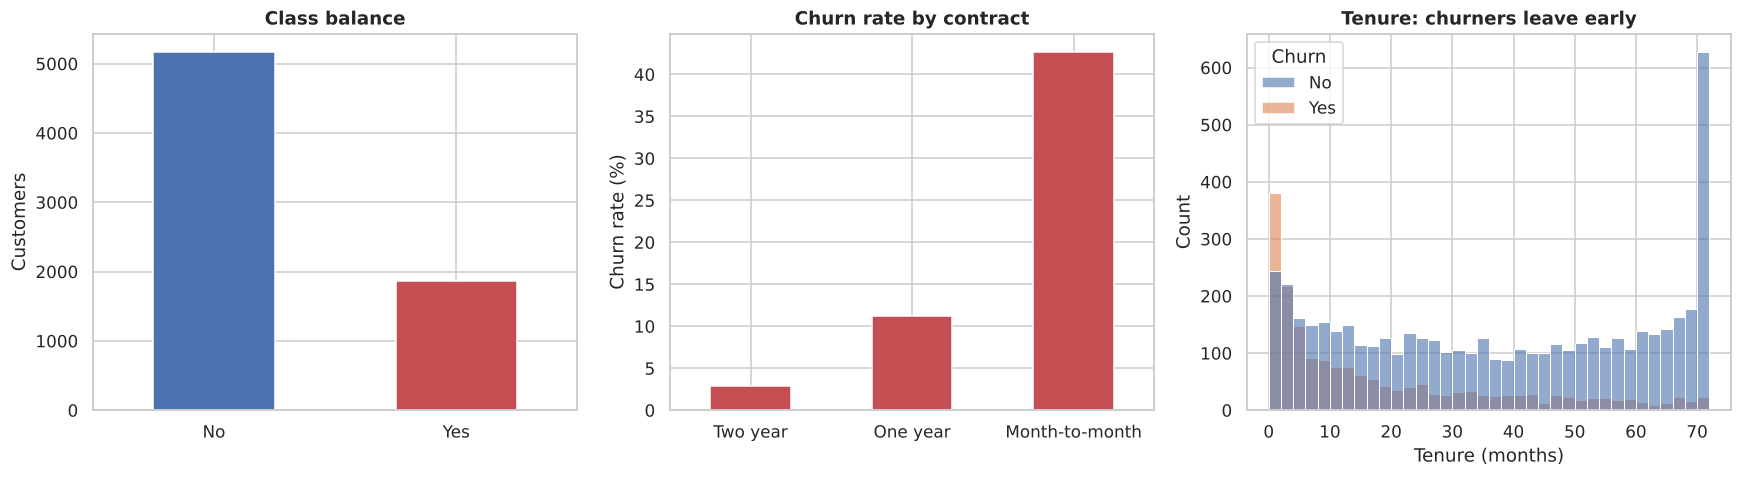

In [5]:
churn_rate = (df["Churn"] == "Yes").mean()
print(f"Overall churn rate: {churn_rate:.1%}  ({(df['Churn'] == 'Yes').sum():,} of {len(df):,} customers)")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Class balance
df["Churn"].value_counts().plot.bar(ax=axes[0], color=["#4C72B0", "#C44E52"], rot=0)
axes[0].set(title="Class balance", xlabel="", ylabel="Customers")

# Churn rate by contract type
(df.groupby("Contract")["Churn"].apply(lambda s: (s == "Yes").mean() * 100)
   .sort_values().plot.bar(ax=axes[1], color="#C44E52", rot=0))
axes[1].set(title="Churn rate by contract", xlabel="", ylabel="Churn rate (%)")

# Tenure distribution by churn
sns.histplot(data=df, x="tenure", hue="Churn", bins=36, multiple="layer", alpha=0.6, ax=axes[2])
axes[2].set(title="Tenure: churners leave early", xlabel="Tenure (months)")

plt.tight_layout()
plt.savefig("images/eda_overview.png", bbox_inches="tight")
plt.show()

**What the data says**
- Only ~26.5% of customers churn → the classes are **imbalanced**, which is why we use SMOTE later.
- **Month-to-month** contracts churn far more than 1- or 2-year contracts.
- Most churners leave in their **first few months**: early tenure is the danger zone.

## 5. Feature engineering

- Drop `customerID` (identifier, no predictive signal)
- One-hot encode all categorical columns (`drop_first=True` to avoid the dummy-variable trap)
- Map the target `Churn` → `Yes = 1`, `No = 0`

In [6]:
df_model = df.drop(columns=["customerID"])

cat_cols = df_model.select_dtypes(include=["object", "string"]).columns.drop("Churn")
df_encoded = pd.get_dummies(df_model, columns=cat_cols, drop_first=True)
df_encoded["Churn"] = df_encoded["Churn"].map({"Yes": 1, "No": 0})

print(f"Encoded shape: {df_encoded.shape}  ({len(cat_cols)} categorical columns expanded)")

Encoded shape: (7043, 31)  (15 categorical columns expanded)


## 6. Train / test split + SMOTE

- **Stratified** 80/20 split keeps the churn ratio identical in train and test.
- **SMOTE is applied only to the training set.** Resampling the test set would leak synthetic data into the evaluation and inflate the scores.

In [7]:
X = df_encoded.drop(columns=["Churn"])
y = df_encoded["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

X_train_res, y_train_res = SMOTE(random_state=RANDOM_STATE).fit_resample(X_train, y_train)

balance = pd.DataFrame({
    "Train (original)": y_train.value_counts(),
    "Train (after SMOTE)": y_train_res.value_counts(),
    "Test (untouched)": y_test.value_counts(),
}).rename_axis("Churn")
balance

,Train (original),Train (after SMOTE),Test (untouched)
Churn,,,
0,4139,4139,1035
1,1495,4139,374


## 7. Modelling

One helper trains each model and records the same metrics, so there is no copy-pasted evaluation code.
Logistic Regression is distance/scale-sensitive so it gets **standardised** inputs (scaler fit on train only).
Tree models don't need scaling.

In [8]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_res)
X_test_scaled = scaler.transform(X_test)

models = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
                            X_train_scaled, X_test_scaled),
    "Random Forest": (RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
                      X_train_res, X_test),
    "XGBoost": (XGBClassifier(n_estimators=100, random_state=RANDOM_STATE, eval_metric="logloss"),
                X_train_res, X_test),
}

fitted, preds, probas, rows = {}, {}, {}, []
for name, (model, Xtr, Xte) in models.items():
    model.fit(Xtr, y_train_res)
    preds[name] = model.predict(Xte)
    probas[name] = model.predict_proba(Xte)[:, 1]
    fitted[name] = model

    p, r, f, _ = precision_recall_fscore_support(y_test, preds[name], labels=[1], zero_division=0)
    rows.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test, probas[name]),
        "Recall (Churn)": r[0],
        "Precision (Churn)": p[0],
        "F1 (Churn)": f[0],
        "Accuracy": (preds[name] == y_test).mean(),
    })

results = pd.DataFrame(rows).set_index("Model").round(3)
results

,ROC-AUC,Recall (Churn),Precision (Churn),F1 (Churn),Accuracy
Model,,,,,
Logistic Regression,0.813,0.634,0.545,0.586,0.762
Random Forest,0.820,0.583,0.571,0.577,0.773
XGBoost,0.816,0.596,0.575,0.585,0.776


### Detailed report for each model

In [9]:
for name in models:
    print(f"{'=' * 12} {name} {'=' * 12}")
    print(classification_report(y_test, preds[name], target_names=["Stay", "Churn"]))

============ Logistic Regression ============
              precision    recall  f1-score   support

        Stay       0.86      0.81      0.83      1035
       Churn       0.54      0.63      0.59       374

    accuracy                           0.76      1409
   macro avg       0.70      0.72      0.71      1409
weighted avg       0.78      0.76      0.77      1409

============ Random Forest ============
              precision    recall  f1-score   support

        Stay       0.85      0.84      0.84      1035
       Churn       0.57      0.58      0.58       374

    accuracy                           0.77      1409
   macro avg       0.71      0.71      0.71      1409
weighted avg       0.77      0.77      0.77      1409

============ XGBoost ============
              precision    recall  f1-score   support

        Stay       0.85      0.84      0.85      1035
       Churn       0.57      0.60      0.59       374

    accuracy                           0.78      1409
   macro

## 8. Model comparison

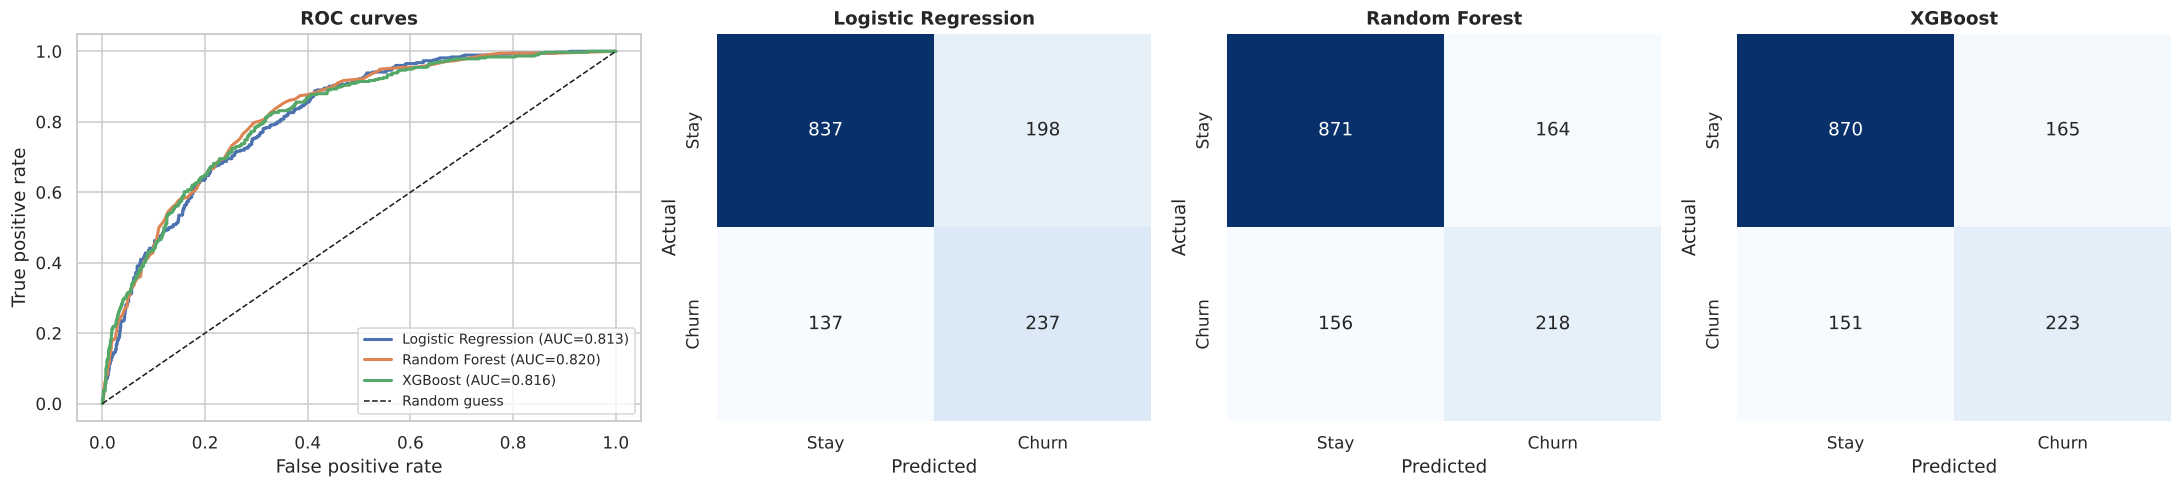

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.6), gridspec_kw={"width_ratios": [1.3, 1, 1, 1]})

# ROC curves
for name in models:
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    axes[0].plot(fpr, tpr, lw=2, label=f"{name} (AUC={roc_auc_score(y_test, probas[name]):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Random guess")
axes[0].set(title="ROC curves", xlabel="False positive rate", ylabel="True positive rate")
axes[0].legend(loc="lower right", fontsize=9)

# Confusion matrices
for ax, name in zip(axes[1:], models):
    sns.heatmap(confusion_matrix(y_test, preds[name]), annot=True, fmt="d", cmap="Blues",
                cbar=False, ax=ax, xticklabels=["Stay", "Churn"], yticklabels=["Stay", "Churn"])
    ax.set(title=name, xlabel="Predicted", ylabel="Actual")

plt.tight_layout()
plt.savefig("images/model_comparison.png", bbox_inches="tight")
plt.show()

**Takeaways**
- All three models land at **ROC-AUC ≈ 0.81–0.82**: on this dataset the features, not the algorithm, are the ceiling.
- **Logistic Regression catches the most churners (recall 0.63)** at the cost of more false alarms.
- Random Forest has the best AUC, but misses more churners (recall 0.58).
- Since a lost customer costs more than an unnecessary retention offer, I picked **Logistic Regression** as the model to ship.

## 9. Does SMOTE actually help?

A fair check: train the **same three models** on the original (imbalanced) training data and compare against the SMOTE versions on the same untouched test set.

In [11]:
def make_pipeline(name, use_smote):
    """Same models and settings as above; SMOTE (if used) runs inside the pipeline."""
    base = {
        "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
        "XGBoost": XGBClassifier(n_estimators=100, random_state=RANDOM_STATE, eval_metric="logloss"),
    }[name]
    steps = [("smote", SMOTE(random_state=RANDOM_STATE))] if use_smote else []
    if name == "Logistic Regression":
        steps.append(("scale", StandardScaler()))
    return Pipeline(steps + [("model", base)])

rows = []
for name in models:
    for use_smote in (False, True):
        proba = make_pipeline(name, use_smote).fit(X_train, y_train).predict_proba(X_test)[:, 1]
        pred = proba >= 0.5
        rows.append({"Model": name, "SMOTE": "yes" if use_smote else "no",
                     "ROC-AUC": roc_auc_score(y_test, proba),
                     "Recall (Churn)": recall_score(y_test, pred),
                     "Precision (Churn)": precision_score(y_test, pred)})

smote_check = pd.DataFrame(rows).set_index(["Model", "SMOTE"]).round(3)
smote_check

ROC-AUC  Recall (Churn)  Precision (Churn)
Model               SMOTE                                            
Logistic Regression no       0.842           0.567              0.658
                    yes      0.813           0.634              0.545
Random Forest       no       0.825           0.508              0.615
                    yes      0.820           0.586              0.560
XGBoost             no       0.818           0.521              0.589
                    yes      0.816           0.596              0.575

**Finding:** SMOTE does **not** improve ranking quality (ROC-AUC is the same or *lower* with it, notably for Logistic Regression: 0.842 → 0.813).
What it does is push the model to flag more churners at the default 0.5 cutoff (higher recall, lower precision).
That is a **threshold effect**, which we can also get directly by tuning the cutoff (section 11).

## 10. 5-fold cross-validation

A single train/test split can be lucky or unlucky. Here SMOTE sits **inside** the pipeline, so it is re-fit on each training fold only (no leakage into the validation fold). Scores are `mean ± std` over 5 folds on the training data.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_rows = []
for name in models:
    res = cross_validate(make_pipeline(name, use_smote=True), X_train, y_train, cv=cv,
                         scoring=["roc_auc", "recall", "precision"])
    cv_rows.append({
        "Model": name,
        "ROC-AUC": f"{res['test_roc_auc'].mean():.3f} ± {res['test_roc_auc'].std():.3f}",
        "Recall (Churn)": f"{res['test_recall'].mean():.3f} ± {res['test_recall'].std():.3f}",
        "Precision (Churn)": f"{res['test_precision'].mean():.3f} ± {res['test_precision'].std():.3f}",
    })

pd.DataFrame(cv_rows).set_index("Model")

,ROC-AUC,Recall (Churn),Precision (Churn)
Model,,,
Logistic Regression,0.834 ± 0.016,0.642 ± 0.049,0.593 ± 0.023
Random Forest,0.818 ± 0.014,0.567 ± 0.024,0.590 ± 0.024
XGBoost,0.814 ± 0.008,0.572 ± 0.024,0.579 ± 0.022


**Finding:** the ranking holds up across folds: Logistic Regression is as good as or better than the tree models, with the highest recall. The small standard deviations (~0.01–0.02 AUC) show the results are stable, not a lucky split.

## 11. Tuning the decision threshold

`predict()` uses a 0.5 cutoff, but a missed churner costs more than a wasted retention offer.
To pick a better cutoff **without touching the test set**, I take out-of-fold probabilities on the training data (via cross-validation) and choose the threshold that maximises **F2** (recall weighted 2× more than precision). Then I evaluate that single threshold on the test set.

In [13]:
lr_pipe = make_pipeline("Logistic Regression", use_smote=True)

oof_proba = cross_val_predict(lr_pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
thresholds = np.arange(0.10, 0.90, 0.01)
f2_scores = [fbeta_score(y_train, oof_proba >= t, beta=2) for t in thresholds]
best_t = thresholds[int(np.argmax(f2_scores))]

test_proba = lr_pipe.fit(X_train, y_train).predict_proba(X_test)[:, 1]
print(f"Best threshold (chosen on train CV): {best_t:.2f}\n")

compare = []
for label, t in [("Default 0.50", 0.5), (f"Tuned {best_t:.2f}", best_t)]:
    pred = test_proba >= t
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    compare.append({"Threshold": label, "Recall": recall_score(y_test, pred),
                    "Precision": precision_score(y_test, pred),
                    "Churners caught": f"{tp} / {tp + fn}", "False alarms": fp})
pd.DataFrame(compare).set_index("Threshold").round(3)

Best threshold (chosen on train CV): 0.21



,Recall,Precision,Churners caught,False alarms
Threshold,,,,
Default 0.50,0.634,0.545,237 / 374,198
Tuned 0.21,0.896,0.425,335 / 374,453


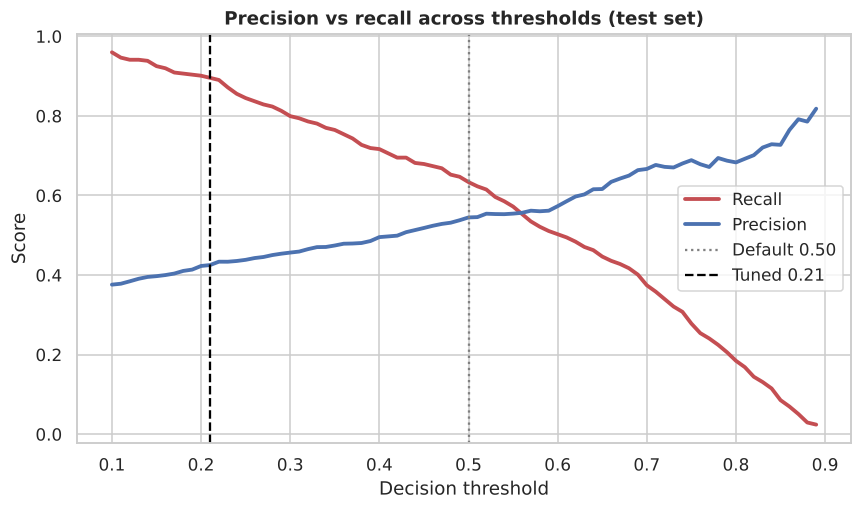

In [14]:
prec_r = [precision_score(y_test, test_proba >= t) for t in thresholds]
rec_r = [recall_score(y_test, test_proba >= t) for t in thresholds]

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(thresholds, rec_r, lw=2.5, label="Recall", color="#C44E52")
ax.plot(thresholds, prec_r, lw=2.5, label="Precision", color="#4C72B0")
ax.axvline(0.5, color="grey", ls=":", label="Default 0.50")
ax.axvline(best_t, color="black", ls="--", label=f"Tuned {best_t:.2f}")
ax.set(title="Precision vs recall across thresholds (test set)", xlabel="Decision threshold", ylabel="Score")
ax.legend()
plt.tight_layout()
plt.savefig("images/threshold_tuning.png", bbox_inches="tight")
plt.show()

**Finding:** lowering the cutoff trades precision for a big jump in recall: the model catches far more churners and sends more unnecessary offers. Which point is "right" depends on the cost of a retention offer vs. the value of a retained customer, a business decision, not a modelling one.

## 12. What drives churn?

Top Random Forest feature importances. (Logistic Regression coefficients are skipped on purpose: many features overlap, e.g. `MonthlyCharges` vs. the service columns, so single coefficients can be misleading.)

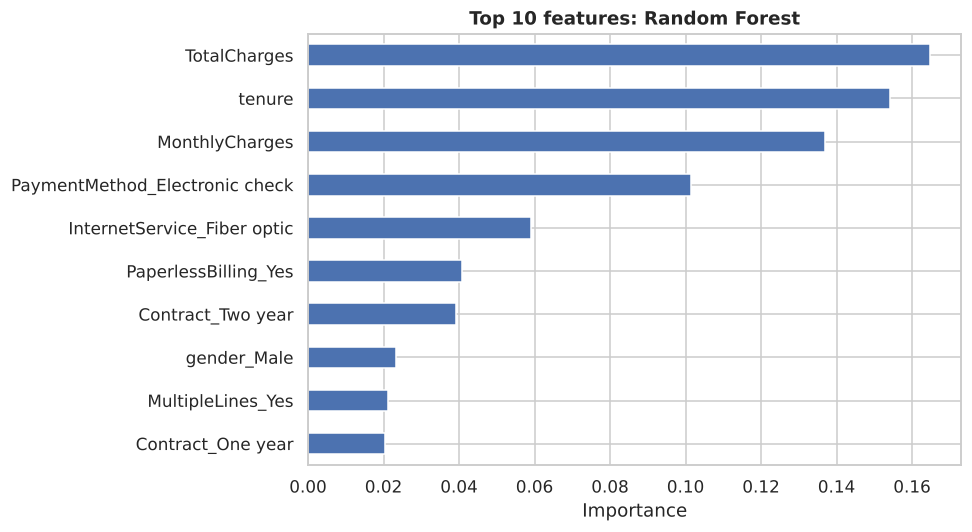

In [15]:
rf_imp = pd.Series(fitted["Random Forest"].feature_importances_, index=X.columns).nlargest(10)

ax = rf_imp.sort_values().plot.barh(figsize=(9, 5), color="#4C72B0")
ax.set(title="Top 10 features: Random Forest", xlabel="Importance")
plt.tight_layout()
plt.savefig("images/feature_importance.png", bbox_inches="tight")
plt.show()

**Reading it:** `TotalCharges`, `tenure` and `MonthlyCharges` dominate, followed by **electronic-check payment**, **fiber-optic internet** and contract type. This matches the EDA: new, high-bill, month-to-month customers are the highest risk.

## 13. Saved model

The model I trained and saved is the **Logistic Regression** above, together with its **scaler**: new data must be scaled *exactly* the same way before prediction.
Both files are in `models/`. Here I reload them and re-score the test set to confirm they work.

> To retrain and overwrite them, set `SAVE_MODELS = True`.

In [16]:
SAVE_MODELS = False   # the shipped .pkl files are the originals; flip to True to overwrite them

if SAVE_MODELS:
    joblib.dump(fitted["Logistic Regression"], "models/churn_model.pkl")
    joblib.dump(scaler, "models/scaler.pkl")

model = joblib.load("models/churn_model.pkl")
scaler_loaded = joblib.load("models/scaler.pkl")

proba = model.predict_proba(scaler_loaded.transform(X_test))[:, 1]
print(f"Saved model ROC-AUC: {roc_auc_score(y_test, proba):.4f}")
print("Confusion matrix:")
print(confusion_matrix(y_test, proba >= 0.5))

Saved model ROC-AUC: 0.8128
Confusion matrix:
[[836 199]
 [137 237]]


## 14. Conclusion & next steps

**Results**
- ROC-AUC ≈ **0.81–0.84** depending on setup; all three models perform similarly, so the features are the limit.
- At the default cutoff the saved Logistic Regression catches **63%** of churners; with a tuned threshold it catches **~90%** (at the cost of more false alarms).
- SMOTE did not improve ranking quality; its benefit was mostly a shift in the decision threshold.
- 5-fold CV confirms the results are stable.

**Business insight:** target **month-to-month, short-tenure, high-bill** customers first.

**Next steps**
- Hyperparameter tuning (`GridSearchCV` / Optuna)
- Retrain the final model without SMOTE and with the tuned threshold
- SHAP for per-customer explanations
- Wrap the model in a Streamlit / FastAPI app